Using dataset: C:\Users\isura\.cache\kagglehub\datasets\mlg-ulb\creditcardfraud\versions\3\creditcard.csv
Dataset shape: (284807, 31)


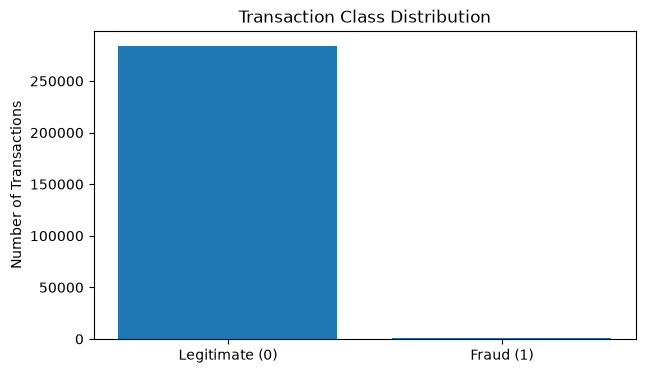

Fraud rate in the loaded dataset: 0.173%


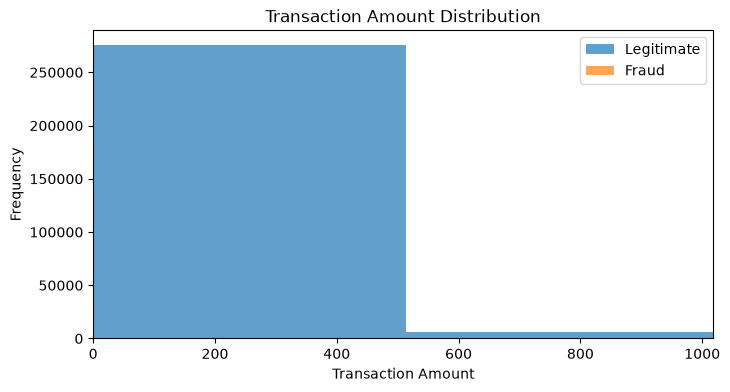

Training samples: 227845
Testing samples: 56962

Training class distribution:
Class
0    227451
1       394
Name: count, dtype: int64
Training Logistic Regression...
Training Decision Tree...
Training KNN...
Training Naive Bayes...
Training SVM...


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
2,KNN,0.9995,0.9186,0.8061,0.8587,0.9437,0.8414
4,SVM,0.9968,0.3217,0.7551,0.4512,0.9732,0.4776
1,Decision Tree,0.9806,0.0693,0.8265,0.1279,0.9075,0.4750
0,Logistic Regression,0.9755,0.0610,0.9184,0.1144,0.9721,0.7190
3,Naive Bayes,0.9764,0.0588,0.8469,0.1099,0.9632,0.0824


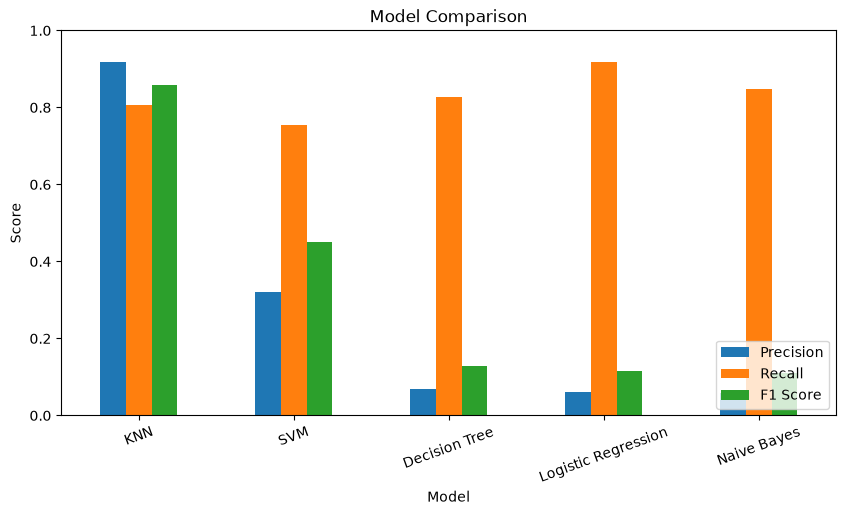

Best model based on F1-score: KNN

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56864
       Fraud       0.92      0.81      0.86        98

    accuracy                           1.00     56962
   macro avg       0.96      0.90      0.93     56962
weighted avg       1.00      1.00      1.00     56962



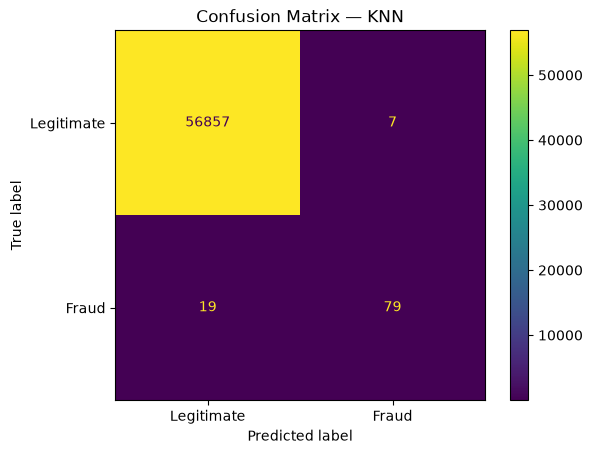

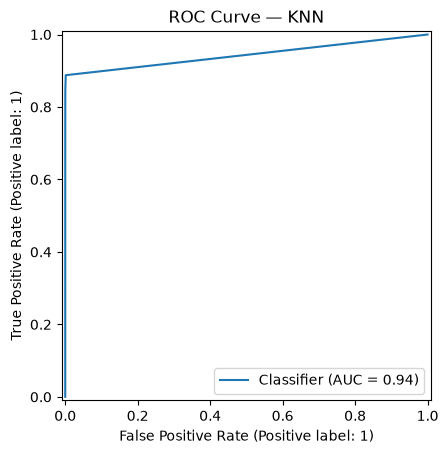

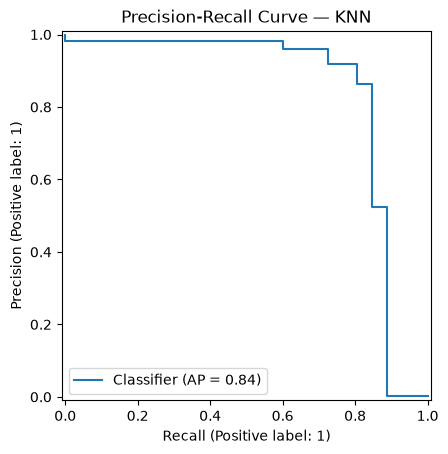

ROC-AUC: 0.9437
PR-AUC: 0.8414
Actual class: Legitimate
Predicted class: Legitimate
Predicted fraud probability: 0.0000


In [4]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score,
    average_precision_score, ConfusionMatrixDisplay
)

RANDOM_STATE = 42

path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")
csv_files = list(Path(path).rglob("creditcard.csv"))

if not csv_files:
    raise FileNotFoundError("creditcard.csv was not found in the downloaded Kaggle dataset.")

DATA_FILE = csv_files[0]
print("Using dataset:", DATA_FILE)

df = pd.read_csv(DATA_FILE)
print("Dataset shape:", df.shape)
df.head()

class_counts = df["Class"].value_counts().sort_index()

plt.figure(figsize=(7, 4))
plt.bar(["Legitimate (0)", "Fraud (1)"], class_counts.values)
plt.title("Transaction Class Distribution")
plt.ylabel("Number of Transactions")
plt.show()

fraud_rate = df["Class"].mean() * 100
print(f"Fraud rate in the loaded dataset: {fraud_rate:.3f}%")

plt.figure(figsize=(8, 4))
plt.hist(df.loc[df["Class"] == 0, "Amount"], bins=50, alpha=0.7, label="Legitimate")
plt.hist(df.loc[df["Class"] == 1, "Amount"], bins=50, alpha=0.7, label="Fraud")
plt.xlim(0, df["Amount"].quantile(0.99))
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")
plt.title("Transaction Amount Distribution")
plt.legend()
plt.show()

X = df.drop(columns=["Class"])
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("\nTraining class distribution:")
print(y_train.value_counts())

models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            class_weight="balanced",
            max_iter=2000,
            random_state=RANDOM_STATE
        ))
    ]),
    
    "Decision Tree": Pipeline([
        ("model", DecisionTreeClassifier(
            class_weight="balanced",
            max_depth=8,
            random_state=RANDOM_STATE
        ))
    ]),
    
    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ]),
    
    "Naive Bayes": Pipeline([
        ("scaler", StandardScaler()),
        ("model", GaussianNB())
    ]),
    
    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(
            class_weight="balanced",
            probability=True,
            random_state=RANDOM_STATE
        ))
    ])
}

results = []
trained_models = {}

for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train, y_train)
    trained_models[name] = model
    
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "PR-AUC": average_precision_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results).sort_values("F1 Score", ascending=False)
results_df

display(results_df.style.format({
    "Accuracy": "{:.4f}",
    "Precision": "{:.4f}",
    "Recall": "{:.4f}",
    "F1 Score": "{:.4f}",
    "ROC-AUC": "{:.4f}",
    "PR-AUC": "{:.4f}"
}))

metric_cols = ["Precision", "Recall", "F1 Score"]

results_plot = results_df.set_index("Model")[metric_cols]
results_plot.plot(kind="bar", figsize=(10, 5))
plt.title("Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.legend(loc="lower right")
plt.show()

best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

best_pred = best_model.predict(X_test)

print("Best model based on F1-score:", best_model_name)
print("\nClassification Report:")
print(classification_report(
    y_test, best_pred,
    target_names=["Legitimate", "Fraud"],
    zero_division=0
))

cm = confusion_matrix(y_test, best_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Legitimate", "Fraud"]
)
disp.plot()
plt.title(f"Confusion Matrix — {best_model_name}")
plt.show()

from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

best_prob = best_model.predict_proba(X_test)[:, 1]

RocCurveDisplay.from_predictions(y_test, best_prob)
plt.title(f"ROC Curve — {best_model_name}")
plt.show()

PrecisionRecallDisplay.from_predictions(y_test, best_prob)
plt.title(f"Precision-Recall Curve — {best_model_name}")
plt.show()

print("ROC-AUC:", round(roc_auc_score(y_test, best_prob), 4))
print("PR-AUC:", round(average_precision_score(y_test, best_prob), 4))

sample = X_test.iloc[[0]]
actual = y_test.iloc[0]

prediction = best_model.predict(sample)[0]
probability = best_model.predict_proba(sample)[0, 1]

print("Actual class:", "Fraud" if actual == 1 else "Legitimate")
print("Predicted class:", "Fraud" if prediction == 1 else "Legitimate")
print(f"Predicted fraud probability: {probability:.4f}")